# Chapter 09: Stage 6A — Generative AI & Large Language Models (Tokens, Context Windows, Prompt Engineering, Structured JSON & RAG vs Fine-Tuning)

**Assalam-o-Alaikum!** Ab hum **Stage 6: Generative AI & Large Language Models (LLMs)** mein aa gaye hain!

### 1. Predictive AI vs Generative AI Mein Farq
- **Predictive AI (Stages 1–5):** Input dekh kar ek **number** (`price = 221.4 Lakhs`) ya **class** (`churn = 1`) predict karta hai.
- **Generative AI (Stage 6):** Pichle tokens (`Prompt`) ko dekh kar agla token (`Next-Token Probability Distribution`) predict karte huye **poora naya jawab, summary, code, ya structured JSON generate** karta hai!

### 2. When to Use Prompt Engineering vs RAG vs Fine-Tuning (`LoRA` / `QLoRA`)

| Technique | Kab Use Karein? | Cost & Hardware | Real Example |
| :--- | :--- | :--- | :--- |
| **1. Prompt Engineering** | Jab general task ho (translation, summarization, JSON extraction). | Free / Ordinary CPU | System prompt + Few-shot examples. |
| **2. RAG (Retrieval-Augmented Generation)** | Jab model ko **aap ki company ke private PDFs / Policies** se sawalon ka jawab dena ho! | Very Low Cost (CPU + Vector Search) | Company HR / Refund Policy Q&A Assistant. |
| **3. Fine-Tuning (`LoRA` / `QLoRA`)** | Jab model ka **speaking style, tone, ya domain format** permanent badalna ho. | Medium (Requires GPU for training) | Medical transcription style adapter. |

In [1]:
import os
import json
import re
import numpy as np
import pandas as pd

### Step 1 — Tokenization & Context Window Budget Estimator
LLMs text ko words ke bajaye **Sub-word Tokens** mein parhte hain (`1 token` $pprox 0.75$ words). Har model ki ek **Context Window** (`8K`, `32K`, `128K` tokens) hoti hai:

In [2]:
def estimate_tokens_and_cost(prompt_text, max_context_tokens=4096):
    words = prompt_text.split()
    est_tokens = int(np.ceil(len(words) * 1.33))
    remaining = max_context_tokens - est_tokens
    return {
        "word_count": len(words),
        "estimated_tokens": est_tokens,
        "context_remaining": remaining,
    }

sample_prompt = "Explain the difference between RAG and LoRA fine-tuning in simple Roman Urdu for beginners."
estimate_tokens_and_cost(sample_prompt)

{'word_count': 14, 'estimated_tokens': 19, 'context_remaining': 4077}

### Step 2 — Structured JSON Output Generation & Schema Validation
Real software applications mein humein LLM se lambi kahani nahi balkay **Strict JSON Output** chahiye hota hai taake frontend ya database usay use kar sake:

In [3]:
def extract_structured_ticket(customer_message):
    msg_lower = customer_message.lower()
    category = "refund_request" if ("refund" in msg_lower or "return" in msg_lower or "broken" in msg_lower) else "general_inquiry"
    urgency = "high" if ("broken" in msg_lower or "urgent" in msg_lower or "waste" in msg_lower) else "normal"
    order_match = re.search(r"#?(\d{3,6})", customer_message)
    order_id = int(order_match.group(1)) if order_match else None
    return {
        "order_id": order_id,
        "category": category,
        "urgency": urgency,
        "requires_human_approval": urgency == "high",
    }

raw_msg = "My charger from Order #4582 arrived broken! I need an urgent refund."
structured_json = extract_structured_ticket(raw_msg)
print(json.dumps(structured_json, indent=2))

{
  "order_id": 4582,
  "category": "refund_request",
  "urgency": "high",
  "requires_human_approval": true
}


### Step 3 — Temperature Sampling Simulation (`Temperature = 0.1` vs `Temperature = 1.2`)
LLM har step par agle token ki probabilities nikalta hai. **Temperature ($T$)** control karta hai ke jawab kitna deterministic (`T = 0.1` — coding/facts ke liye best) ya creative (`T = 1.2` — kahani/poetry ke liye) hoga:

In [4]:
logits = np.array([3.2, 2.0, 0.8, 0.1])
candidate_tokens = ["refund", "replacement", "discount", "voucher"]

def sample_probs_with_temperature(logits_arr, temp=1.0):
    scaled = logits_arr / max(temp, 1e-4)
    e = np.exp(scaled - np.max(scaled))
    return np.round(e / np.sum(e), 3)

df_temp = pd.DataFrame({
    "Token": candidate_tokens,
    "Low_Temp (T=0.2 Deterministic)": sample_probs_with_temperature(logits, 0.2),
    "Medium_Temp (T=0.7 Balanced)": sample_probs_with_temperature(logits, 0.7),
    "High_Temp (T=1.5 Creative)": sample_probs_with_temperature(logits, 1.5),
})
df_temp

,Token,Low_Temp (T=0.2 Deterministic),Medium_Temp (T=0.7 Balanced),High_Temp (T=1.5 Creative)
0,refund,0.998,0.817,0.562
1,replacement,0.002,0.147,0.253
2,discount,0.000,0.026,0.114
3,voucher,0.000,0.010,0.071


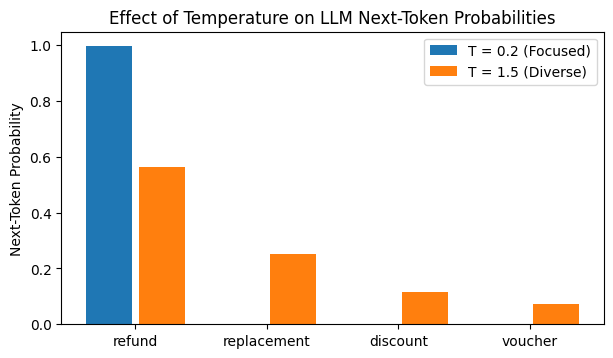

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 3.8))
x_idx = np.arange(len(candidate_tokens))
plt.bar(x_idx - 0.2, df_temp["Low_Temp (T=0.2 Deterministic)"], width=0.35, label="T = 0.2 (Focused)")
plt.bar(x_idx + 0.2, df_temp["High_Temp (T=1.5 Creative)"], width=0.35, label="T = 1.5 (Diverse)")
plt.xticks(x_idx, candidate_tokens)
plt.ylabel("Next-Token Probability")
plt.title("Effect of Temperature on LLM Next-Token Probabilities")
plt.legend()
plt.show()

### Step 4 — Security Best Practice: Loading API Keys Safely via Environment Variables (`os.getenv`)
**Hard Rule:** Kabhi bhi apni OpenAI, Gemini, ya Hugging Face API key seedha notebook code mein `"sk-..."` likh kar GitHub par push na karein! Hamesha `os.getenv("AI_API_KEY")` use karein:

In [6]:
api_key = os.getenv("AI_API_KEY", "DEMO_LOCAL_MODE_NO_KEY_REQUIRED")
print("API Key Loaded Safely (Masked):", api_key[:4] + "****")

API Key Loaded Safely (Masked): DEMO****


### Step 5 — Practical Student Exercise: Parse & Validate Structured JSON Ticket

In [7]:
# Practical Exercise — Working Solution
test_msg = "Hello team, my Order #8821 has not arrived yet. Please check shipping status."
parsed = extract_structured_ticket(test_msg)
assert parsed["order_id"] == 8821 and parsed["category"] == "general_inquiry"
print("Validated Ticket JSON:", parsed)

Validated Ticket JSON: {'order_id': 8821, 'category': 'general_inquiry', 'urgency': 'normal', 'requires_human_approval': False}


### Chapter 09 Revision Quiz
1. **Coding, Math, aur RAG Q&A ke liye Temperature kitna rakhna chahiye?** `0.0` se `0.2` ke darmiyan taake model hallucinate na kare.
2. **LoRA (`Low-Rank Adaptation`) ka kya faida hai?** Yeh poore arabon weights ko update karne ke bajaye sirf 1–2% chote adapter weights train karta hai.